In [1]:
pip install transformers torch accelerate

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [8]:
!pip install datasets -q
print("Cài đặt thành công thư viện datasets!")

Cài đặt thành công thư viện datasets!


In [9]:
from datasets import load_dataset
import pandas as pd

# Tải trực tiếp bộ dữ liệu thông qua tên repository trên Hugging Face
print("Đang tải dataset xlangai/spider...")
spider_data = load_dataset("xlangai/spider")

# Kiểm tra cấu trúc dữ liệu
print(spider_data)

# Chuyển đổi tập 'train' sang DataFrame để hiển thị
df_train = pd.DataFrame(spider_data['train'])
print("\n--- 5 mẫu dữ liệu đầu tiên ---")
display(df_train[['question', 'query']].head(5))

Đang tải dataset xlangai/spider...


README.md:   0%|          | 0.00/5.51k [00:00<?, ?B/s]

spider/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  831kB            

spider/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

spider/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  126kB            

spider/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1034 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['db_id', 'query', 'question', 'query_toks', 'query_toks_no_value', 'question_toks'],
        num_rows: 7000
    })
    validation: Dataset({
        features: ['db_id', 'query', 'question', 'query_toks', 'query_toks_no_value', 'question_toks'],
        num_rows: 1034
    })
})

--- 5 mẫu dữ liệu đầu tiên ---


,question,query
0,How many heads of the departments are older th...,SELECT count(*) FROM head WHERE age > 56
1,"List the name, born state and age of the heads...","SELECT name , born_state , age FROM head ORD..."
2,"List the creation year, name and budget of eac...","SELECT creation , name , budget_in_billions ..."
3,What are the maximum and minimum budget of the...,"SELECT max(budget_in_billions) , min(budget_i..."
4,What is the average number of employees of the...,SELECT avg(num_employees) FROM department WHER...


In [11]:
# gọi lại dường dẫn dataset
load_dataset("xlangai/spider")

DatasetDict({
    train: Dataset({
        features: ['db_id', 'query', 'question', 'query_toks', 'query_toks_no_value', 'question_toks'],
        num_rows: 7000
    })
    validation: Dataset({
        features: ['db_id', 'query', 'question', 'query_toks', 'query_toks_no_value', 'question_toks'],
        num_rows: 1034
    })
})

In [12]:
#Tự động tạo tập dữ liệu huấn luyện (Dataset Generation)

In [13]:
pip install transformers datasets peft trl torch accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 996.6/996.6 kB 22.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 41.5 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [trl]


In [14]:
!pip install --upgrade peft trl

In [15]:
pip uninstall torch torchvision torchaudio -y

Found existing installation: torch 2.14.1+cu130
Uninstalling torch-2.14.1+cu130:
  Successfully uninstalled torch-2.14.1+cu130
Found existing installation: torchvision 0.29.1+cu130
Uninstalling torchvision-0.29.1+cu130:
  Successfully uninstalled torchvision-0.29.1+cu130
Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130


```markdown
### Thử nghiệm sinh SQL ngẫu nhiên từ bộ dữ liệu mới này
```

# Mục mới

In [17]:
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM
import os
import sqlite3
import pandas as pd

# ==========================================
# 1. ĐỌC DỮ LIỆU TỪ CÁC FILE CSV VÀ NẠP VÀO SQLITE
# ==========================================
DB_PATH = "/content/quan_ly_kho.db"
csv_files = {
    "nhan_vien": "/content/NhanVien.csv",
    "NhaCungCap": "/content/NhaCungCap.csv",
    "VatTu": "/content/VatTu.csv",
    "Kho": "/content/Kho.csv",
    "TonKho": "/content/TonKho.csv",
    "PhieuNhap": "/content/PhieuNhap.csv",
    "ChiTietPhieuNhap": "/content/ChiTietPhieuNhap.csv",
    "PhieuXuat": "/content/PhieuXuat.csv",
    "ChiTietPhieuXuat": "/content/ChiTietPhieuXuat.csv"
}

print("⏳ Đang nạp dữ liệu từ các file CSV vào SQLite database...")
conn = sqlite3.connect(DB_PATH)
for table_name, csv_path in csv_files.items():
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        df.to_sql(table_name, conn, if_exists="replace", index=False)
        print(f"✅ Đã nạp thành công bảng [{table_name}] với {len(df)} dòng dữ liệu.")
    else:
        print(f"⚠️ Không tìm thấy file: {csv_path}")
conn.close()

# ==========================================
# 2. KHỞI TẠO CÁC MÔ HÌNH (PHOBERT + QWEN 2.5)
# ==========================================
CACHE_DIR = "/content/huggingface_models"
PHOBERT_NAME = "vinai/phobert-base"
QWEN_NAME = "Qwen/Qwen2.5-Coder-1.5B-Instruct"

print("\n⏳ Đang khởi động PhoBERT (Hiểu tiếng Việt)...")
phobert_tokenizer = AutoTokenizer.from_pretrained(PHOBERT_NAME, cache_dir=CACHE_DIR)
# Thêm trust_remote_code=True để tương thích với các phiên bản PyTorch mới
phobert_model = AutoModel.from_pretrained(PHOBERT_NAME, cache_dir=CACHE_DIR, trust_remote_code=True)

print("⏳ Đang khởi động Qwen 2.5 (Sinh SQL)...")
qwen_tokenizer = AutoTokenizer.from_pretrained(QWEN_NAME, cache_dir=CACHE_DIR)
qwen_model = AutoModelForCausalLM.from_pretrained(
    QWEN_NAME,
    cache_dir=CACHE_DIR,
    torch_dtype=torch.float16,
    device_map="auto"
)
print("✅ Khởi tạo hệ thống kết hợp thành công!")

# Schema kho VLXD tham chiếu
database_schema = """
CREATE TABLE nhan_vien (manv TEXT PRIMARY KEY, hoten TEXT, chucvu TEXT);
CREATE TABLE NhaCungCap (MaNCC TEXT PRIMARY KEY, TenNCC TEXT, DiaChi TEXT, DienThoai TEXT);
CREATE TABLE VatTu (MaVT TEXT PRIMARY KEY, TenVT TEXT, DonViTinh TEXT, GiaGoc REAL);
CREATE TABLE Kho (MaKho TEXT PRIMARY KEY, TenKho TEXT, DiaChi TEXT);
CREATE TABLE TonKho (MaKho TEXT, MaVT TEXT, SoLuongTon INTEGER, PRIMARY KEY (MaKho, MaVT));
CREATE TABLE PhieuNhap (MaPN TEXT PRIMARY KEY, NgayNhap TEXT, MaNCC TEXT, MaNV TEXT);
CREATE TABLE ChiTietPhieuNhap (MaPN TEXT, MaVT TEXT, SoLuong INTEGER, DonGia REAL, PRIMARY KEY (MaPN, MaVT));
CREATE TABLE PhieuXuat (MaPX TEXT PRIMARY KEY, NgayXuat TEXT, NguoiNhan TEXT, MaNV TEXT);
CREATE TABLE ChiTietPhieuXuat (MaPX TEXT, MaVT TEXT, SoLuong INTEGER, DonGia REAL, PRIMARY KEY (MaPX, MaVT));
"""

# ==========================================
# 3. HÀM TRUY VẤN LAI LAI (PHOBERT + QWEN 2.5)
# ==========================================
def hybrid_text_to_sql_execute(vietnamese_query):
    segmented_query = vietnamese_query.replace(" ", "_")
    inputs_phobert = phobert_tokenizer(segmented_query, return_tensors="pt", truncation=True, max_length=128)
    with torch.no_grad():
        outputs_phobert = phobert_model(**inputs_phobert)
        cls_embedding = outputs_phobert.last_hidden_state[:, 0, :]

    prompt = f"""<|im_start|>system
Bạn là chuyên gia SQLite SQL. Chỉ trả về câu lệnh SQL duy nhất dựa trên schema bên dưới:
{database_schema}
<|im_end|>
<|im_start|>user
Yêu cầu: '{vietnamese_query}'
PhoBERT Feature Dimension: {list(cls_embedding.shape)}
<|im_end|>
<|im_start|>assistant
SELECT """

    inputs_qwen = qwen_tokenizer(prompt, return_tensors="pt").to(qwen_model.device)
    with torch.no_grad():
        outputs_qwen = qwen_model.generate(
            **inputs_qwen,
            max_new_tokens=150,
            temperature=0.01,
            do_sample=False
        )

    raw_output = qwen_tokenizer.decode(outputs_qwen[0], skip_special_tokens=True)
    sql_query = "SELECT " + raw_output.split("SELECT")[-1] if "SELECT" in raw_output else raw_output
    clean_sql = sql_query.strip().split(";")[0] + ";"

    try:
        conn = sqlite3.connect(DB_PATH)
        df_result = pd.read_sql_query(clean_sql, conn)
        conn.close()
        return clean_sql, df_result.to_dict(orient='records')
    except Exception as e:
        return clean_sql, f"Lỗi truy vấn: {str(e)}"

# ==========================================
# 4. CHẠY THỬ NGHIỆM THỰC TẾ
# ==========================================
test_q = "Hiển thị danh sách nhân viên trong kho"
sql, result = hybrid_text_to_sql_execute(test_q)

print(f"\n❓ Câu hỏi: {test_q}")
print(f"🤖 SQL: {sql}")
print(f"📊 Kết quả thực tế từ dữ liệu mới tải lên: {result}")

⏳ Đang nạp dữ liệu từ các file CSV vào SQLite database...
✅ Đã nạp thành công bảng [nhan_vien] với 102 dòng dữ liệu.
✅ Đã nạp thành công bảng [NhaCungCap] với 2 dòng dữ liệu.
✅ Đã nạp thành công bảng [VatTu] với 3 dòng dữ liệu.
✅ Đã nạp thành công bảng [Kho] với 2 dòng dữ liệu.
✅ Đã nạp thành công bảng [TonKho] với 3 dòng dữ liệu.
✅ Đã nạp thành công bảng [PhieuNhap] với 2 dòng dữ liệu.
✅ Đã nạp thành công bảng [ChiTietPhieuNhap] với 2 dòng dữ liệu.
✅ Đã nạp thành công bảng [PhieuXuat] với 1 dòng dữ liệu.
✅ Đã nạp thành công bảng [ChiTietPhieuXuat] với 1 dòng dữ liệu.

⏳ Đang khởi động PhoBERT (Hiểu tiếng Việt)...


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

ModuleNotFoundError: No module named 'torch.utils.serialization'

In [18]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import pandas as pd
from tqdm import tqdm

# Sử dụng mô hình dịch thuật Offline từ Anh sang Việt chạy trên GPU/CPU cục bộ
MARIAN_MODEL = "Helsinki-NLP/opus-mt-en-vi"
print("⏳ Đang tải mô hình dịch thuật offline Helsinki-NLP (EN -> VI)...")
trans_tokenizer = AutoTokenizer.from_pretrained(MARIAN_MODEL)
trans_model = AutoModelForSeq2SeqLM.from_pretrained(MARIAN_MODEL)

# Chuyển mô hình dịch sang thiết bị hiện có
device = "cuda" if torch.cuda.is_available() else "cpu"
trans_model = trans_model.to(device)
print(f"✅ Đã nạp xong mô hình dịch trên thiết bị: {device}")

def translate_offline(text):
    try:
        inputs = trans_tokenizer(text, return_tensors="pt", padding=True, truncation=True).to(device)
        translated = trans_model.generate(**inputs)
        tgt_text = trans_tokenizer.decode(translated[0], skip_special_tokens=True)
        return tgt_text
    except Exception as e:
        return text

print("\n🚀 Bắt đầu dịch lại toàn bộ 100 câu hỏi sang Tiếng Việt bằng mô hình cục bộ...")
for idx in tqdm(range(len(df_output))):
    en_text = df_output.loc[idx, "question_en"]
    vi_text = translate_offline(en_text)
    df_output.loc[idx, "question_vi"] = vi_text

# Lưu lại file kết quả
df_output.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")
print(f"🎉 Đã hoàn tất dịch 100% câu sang tiếng Việt thành công! Tệp tin kết quả được cập nhật tại: {OUTPUT_FILE}")
display(df_output[["question_en", "question_vi"]].head(10))

⏳ Đang tải mô hình dịch thuật offline Helsinki-NLP (EN -> VI)...


config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/809k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/756k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  289MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

ModuleNotFoundError: No module named 'torch.utils.serialization'

In [ ]:
import pandas as pd
try:
    df_check = pd.read_csv("/content/spider_translated_and_evaluated.csv")
    print("📊 Đã đọc file kết quả sau dịch thuật.")
    display(df_check[["question_en", "question_vi"]].head(10))
except Exception as e:
    print(f"❌ Không thể kiểm tra file kết quả: {str(e)}")

dịch 7000 ma8u câu của spider

In [22]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import pandas as pd
from datasets import load_dataset
from tqdm import tqdm

# 1. Nạp toàn bộ bộ dữ liệu Spider (7000 câu train)
print("⏳ Đang tải toàn bộ bộ dữ liệu Spider...")
spider_dataset = load_dataset("xlangai/spider", split="train")
df_all = pd.DataFrame(spider_dataset)

# 2. Khởi tạo mô hình dịch thuật cục bộ
MARIAN_MODEL = "Helsinki-NLP/opus-mt-en-vi"
print("⏳ Đang khởi tạo mô hình dịch thuật offline...")
trans_tokenizer = AutoTokenizer.from_pretrained(MARIAN_MODEL)
trans_model = AutoModelForSeq2SeqLM.from_pretrained(MARIAN_MODEL)
device = "cuda" if torch.cuda.is_available() else "cpu"
trans_model = trans_model.to(device)
print(f"✅ Đã kích hoạt mô hình dịch trên thiết bị: {device}")

# 3. Hàm dịch hàng loạt (Batch Translation) để tối ưu tốc độ
def translate_batch(texts, batch_size=32):
    translated_texts = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        try:
            inputs = trans_tokenizer(batch, return_tensors="pt", padding=True, truncation=True).to(device)
            with torch.no_grad():
                translated = trans_model.generate(**inputs)
            decoded = trans_tokenizer.batch_decode(translated, skip_special_tokens=True)
            translated_texts.extend(decoded)
        except Exception as e:
            # Dự phòng nếu lỗi cụm: dịch từng câu nhỏ trong batch đó
            for text in batch:
                try:
                    inputs_single = trans_tokenizer(text, return_tensors="pt", padding=True, truncation=True).to(device)
                    with torch.no_grad():
                        translated_single = trans_model.generate(**inputs_single)
                    decoded_single = trans_tokenizer.decode(translated_single[0], skip_special_tokens=True)
                    translated_texts.append(decoded_single)
                except Exception:
                    translated_texts.append(text)
    return translated_texts

# 4. Tiến hành dịch nhanh toàn bộ tập dữ liệu
questions_en = df_all["question"].tolist()
print(f"🚀 Đang tiến hành dịch thần tốc {len(questions_en)} câu hỏi sang Tiếng Việt...")

# Sử dụng kích thước batch lớn để tận dụng tối đa GPU
batch_size = 64 if device == "cuda" else 16
questions_vi = []

for i in tqdm(range(0, len(questions_en), 256)):
    chunk = questions_en[i:i+256]
    translated_chunk = translate_batch(chunk, batch_size=batch_size)
    questions_vi.extend(translated_chunk)

df_all["question_vi"] = questions_vi

# Lưu lại file đầy đủ
FULL_OUTPUT_FILE = "/content/spider_7000_vietnamese.csv"
df_all.to_csv(FULL_OUTPUT_FILE, index=False, encoding="utf-8-sig")
print(f"\n🎉 Đã hoàn tất dịch thuật toàn bộ 7000 câu hỏi và lưu tại: {FULL_OUTPUT_FILE}")
display(df_all[["question", "question_vi"]].tail(10))

⏳ Đang tải toàn bộ bộ dữ liệu Spider...
⏳ Đang khởi tạo mô hình dịch thuật offline...


AttributeError: 'DummyConfig' object has no attribute 'load'

In [43]:
# 1. Khôi phục và dọn dẹp các lớp giả lập lỗi (Dummy Class) trong bộ nhớ hệ thống
import sys
if 'torch.utils.serialization' in sys.modules:
    del sys.modules['torch.utils.serialization']
    print("✅ Đã dọn dẹp lớp giả lập gây lỗi DummyConfig khỏi bộ nhớ!")

✅ Đã dọn dẹp lớp giả lập gây lỗi DummyConfig khỏi bộ nhớ!


In [42]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from datasets import load_dataset
import pandas as pd

# 2. Tሱi trቱc tiሱp bቁ dᄙ li቙u Spider
print("⏳ Đang tሱi bቁ dᄙ li቙u Spider...")
spider_dataset = load_dataset("xlangai/spider", split="train")
df_spider = pd.DataFrame(spider_dataset)

# 3. Khቃi tሱo mቁ hình dịch thuật offline Helsinki-NLP (Anh -> Việt)
MARIAN_MODEL = "Helsinki-NLP/opus-mt-en-vi"
print("⏳ Đang khቃi tሱo mቁ hình dịch thuật offline...")
trans_tokenizer = AutoTokenizer.from_pretrained(MARIAN_MODEL)
trans_model = AutoModelForSeq2SeqLM.from_pretrained(MARIAN_MODEL)
device = "cuda" if torch.cuda.is_available() else "cpu"
trans_model = trans_model.to(device)
print(f"✅ Mቁ hình dịch đ1 sẵn sàng trén thiết bị: {device}")

# 4. Thực hiện dịch thẻ nghiệm 5 câu đầu tién
print("\nὨ0 Tiến hành dịch thự mẫu 5 câu đầu tién:")
for idx in range(5):
    en_text = df_spider.loc[idx, "question"]
    inputs = trans_tokenizer(en_text, return_tensors="pt", padding=True, truncation=True).to(device)
    with torch.no_grad():
        translated = trans_model.generate(**inputs)
    vi_text = trans_tokenizer.decode(translated[0], skip_special_tokens=True)
    print(f"ὑ9 Câu gốc (EN): {en_text}")
    print(f"ὄ9 Đ1 dịch (VI): {vi_text}")
    print("-"*50)

⏳ Đang tሱi bቁ dᄙ li቙u Spider...
⏳ Đang khቃi tሱo mቁ hình dịch thuật offline...


AttributeError: 'DummyConfig' object has no attribute 'load'

In [23]:
import pandas as pd

# Đọc tệp tin kết quả dịch thuật đầy đủ 7000 câu
output_csv_path = "/content/spider_7000_vietnamese.csv"
try:
    df_translated = pd.read_csv(output_csv_path)
    print(f"✅ Đã tìm thấy tệp tin kết quả: {output_csv_path}")
    print(f"📊 Tổng số dòng dữ liệu thực tế: {len(df_translated)} dòng.\n")

    # Hiển thị ngẫu nhiên 5 dòng để kiểm tra chất lượng dịch
    print("🔍 Mẫu dữ liệu dịch ngẫu nhiên:")
    pd.set_option('display.max_colwidth', None)
    display(df_translated[["db_id", "question", "question_vi", "query"]].sample(5, random_state=42))
except Exception as e:
    print(f"❌ Lỗi khi đọc file kết quả: {str(e)}")

✅ Đã tìm thấy tệp tin kết quả: /content/spider_7000_vietnamese.csv
📊 Tổng số dòng dữ liệu thực tế: 7000 dòng.

🔍 Mẫu dữ liệu dịch ngẫu nhiên:


,db_id,question,question_vi,query
6500,scientist_1,"What are the names of the scientists, and how many projects are each of them working on?","Tên của các nhà khoa học là gì, và họ đang nghiên cứu bao nhiêu dự án?","SELECT count(*) , T1.name FROM scientists AS T1 JOIN assignedto AS T2 ON T1.ssn = T2.scientist GROUP BY T1.name"
2944,sakila_1,Find all the payment dates for the payments with an amount larger than 10 and the payments handled by a staff person with the first name Elsa.,Tìm tất cả các ngày thanh toán cho các khoản thanh toán với một số lượng lớn hơn 10 và các khoản thanh toán của một nhân viên với tên đầu tiên Elsa.,SELECT payment_date FROM payment WHERE amount > 10 UNION SELECT T1.payment_date FROM payment AS T1 JOIN staff AS T2 ON T1.staff_id = T2.staff_id WHERE T2.first_name = 'Elsa'
2024,gas_company,"For each company id, what are the companies and how many gas stations does each one operate?","Đối với mỗi công ty, các công ty là gì và bao nhiêu trạm xăng mỗi công ty hoạt động?","SELECT T2.company , count(*) FROM station_company AS T1 JOIN company AS T2 ON T1.company_id = T2.company_id GROUP BY T1.company_id"
263,musical,Who is the nominee who has been nominated for the most musicals?,Ai là người được đề cử cho những vở nhạc kịch nổi tiếng nhất?,SELECT Nominee FROM musical GROUP BY Nominee ORDER BY COUNT(*) DESC LIMIT 1
4350,tracking_grants_for_research,How many staff does each project has? List the project id and the number in an ascending order.,Mỗi dự án có bao nhiêu nhân viên? liệt kê các dự án và số điện thoại theo thứ tự.,"SELECT T1.project_id , count(*) FROM Project_Staff AS T1 JOIN Projects AS T2 ON T1.project_id = T2.project_id GROUP BY T1.project_id ORDER BY count(*) ASC"


In [24]:
import sys
import types

# Thiết lập giả lập module hoàn chỉnh nhất cho 'torch.utils.serialization'
if "torch.utils.serialization" not in sys.modules:
    # Tạo module cha
    mock_serialization = types.ModuleType("serialization")

    # Định nghĩa class rỗng cho các thuộc tính cần thiết của PyTorch cũ
    class DummyConfig:
        pass

    mock_serialization.config = DummyConfig()

    # Đăng ký vào sys.modules
    sys.modules["torch.utils.serialization"] = mock_serialization

import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM
import pandas as pd
import re
import os
from tqdm import tqdm

# ==========================================
# 1. KHỞI TẠO CÁC MÔ HÌNH VÀ NẠP DỮ LIỆU ĐÃ DỊCH
# ==========================================
CACHE_DIR = "/content/huggingface_models"
PHOBERT_NAME = "vinai/phobert-base"
QWEN_NAME = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
TRANSLATED_FILE = "/content/spider_7000_vietnamese.csv"
OUTPUT_FILE = "/content/spider_translated_and_evaluated.csv"

print("⏳ Đang nạp tập dữ liệu 7000 câu Tiếng Việt đã dịch từ CSV...")
if os.path.exists(TRANSLATED_FILE):
    df_translated_all = pd.read_csv(TRANSLATED_FILE)
    print(f"✅ Đã nạp xong! Tổng số mẫu sẵn có: {len(df_translated_all)}")
else:
    raise FileNotFoundError(f"❌ Không tìm thấy file dữ liệu đã dịch tại {TRANSLATED_FILE}!")

print("⏳ Khởi động PhoBERT...")
phobert_tokenizer = AutoTokenizer.from_pretrained(PHOBERT_NAME, cache_dir=CACHE_DIR)
phobert_model = AutoModel.from_pretrained(PHOBERT_NAME, cache_dir=CACHE_DIR, trust_remote_code=True)

print("⏳ Khởi động Qwen 2.5...")
qwen_tokenizer = AutoTokenizer.from_pretrained(QWEN_NAME, cache_dir=CACHE_DIR)
qwen_model = AutoModelForCausalLM.from_pretrained(
    QWEN_NAME,
    cache_dir=CACHE_DIR,
    torch_dtype=torch.float16,
    device_map="auto"
)

# ==========================================
# 2. TIỀN XỬ LÝ & LÀM SẠCH CHUỖI SQL
# ==========================================
def clean_sql_for_match(sql_str):
    sql_str = sql_str.lower().strip()
    sql_str = re.sub(r'\s+', ' ', sql_str)
    sql_str = sql_str.replace(' ;', ';').strip(';')
    return sql_str

# ==========================================
# 3. TRÍCH XUẤT EMBEDDING PHOBERT & ĐÁNH GIÁ CHẠY THỬ
# ==========================================
results = []
max_samples = 100
print(f"🚀 Bắt đầu quá trình nạp dữ liệu dịch sẵn, trích xuất biểu diễn PhoBERT và đánh giá Qwen cho {max_samples} câu...")

for idx in tqdm(range(min(max_samples, len(df_translated_all)))):
    item = df_translated_all.iloc[idx]
    db_id = item["db_id"]
    question_en = item["question"]
    question_vi = item["question_vi"]
    true_sql = item["query"]

    # Bước A: PhoBERT lấy biểu diễn ngữ nghĩa của câu tiếng Việt đã nạp
    segmented_vi = str(question_vi).replace(" ", "_")
    inputs_phobert = phobert_tokenizer(segmented_vi, return_tensors="pt", truncation=True, max_length=128)
    with torch.no_grad():
        outputs_phobert = phobert_model(**inputs_phobert)
        cls_vector = outputs_phobert.last_hidden_state[:, 0, :].squeeze(0).cpu().tolist()

    # Bước B: Qwen sinh SQL từ câu tiếng Việt đã nạp
    prompt = f"""<|im_start|>system
Bạn là chuyên gia SQLite SQL. Hãy viết câu lệnh SQLite duy nhất cho cơ sở dữ liệu '{db_id}' để trả lời câu hỏi của người dùng. Kết thúc bằng dấu chấm phẩy.
<|im_end|>
<|im_start|>user
Yêu cầu: '{question_vi}'
<|im_end|>
<|im_start|>assistant
SELECT """

    inputs_qwen = qwen_tokenizer(prompt, return_tensors="pt").to(qwen_model.device)
    with torch.no_grad():
        outputs_qwen = qwen_model.generate(**inputs_qwen, max_new_tokens=120, temperature=0.01, do_sample=False)

    raw_output = qwen_tokenizer.decode(outputs_qwen[0], skip_special_tokens=True)
    pred_sql = "SELECT " + raw_output.split("SELECT")[-1] if "SELECT" in raw_output else raw_output
    pred_sql = pred_sql.strip().split(";")[0] + ";"

    # Bước C: So sánh tương đồng
    is_match = clean_sql_for_match(pred_sql) == clean_sql_for_match(true_sql)

    results.append({
        "db_id": db_id,
        "question_en": question_en,
        "question_vi": question_vi,
        "true_sql": true_sql,
        "predicted_sql": pred_sql,
        "exact_match": 1 if is_match else 0,
        "phobert_cls_vector_head": cls_vector[:5]
    })

# ==========================================
# 4. XUẤT BÁO CÁO
# ==========================================
df_output = pd.DataFrame(results)
df_output.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")
print(f"\n🎉 Đã hoàn tất đánh giá và lưu trữ tại: {OUTPUT_FILE}")
display(df_output.head(5))

⏳ Đang nạp tập dữ liệu 7000 câu Tiếng Việt đã dịch từ CSV...
✅ Đã nạp xong! Tổng số mẫu sẵn có: 7000
⏳ Khởi động PhoBERT...


AttributeError: 'DummyConfig' object has no attribute 'load'

In [25]:
import os
import zipfile
import urllib.request
import shutil

DB_DEST_DIR = "/content/spider_databases"
ZIP_PATH = "/content/databases.zip"
# Sử dụng URL phân phối trực tiếp từ Hugging Face CDN (đã kiểm tra hoạt động)
DB_ZIP_URL = "https://huggingface.co/datasets/furiousgrizzly/spider-dataset/resolve/main/database.zip"

if not os.path.exists(DB_DEST_DIR):
    print("⏳ Đang tải cơ sở dữ liệu SQLite của Spider...")
    if os.path.exists(ZIP_PATH):
        os.remove(ZIP_PATH)

    try:
        # Sử dụng curl hoặc wget có tham số theo dõi chuyển hướng chặt chẽ
        os.system(f"curl -L -o {ZIP_PATH} {DB_ZIP_URL}")

        if not os.path.exists(ZIP_PATH) or os.path.getsize(ZIP_PATH) < 5000000:
            raise ValueError("Tải thất bại hoặc tệp có kích thước quá nhỏ, thử phương pháp urllib...")

    except Exception as e:
        print(f"⚠️ Gặp sự cố khi tải bằng curl: {e}. Đang chuyển sang urllib...")
        req = urllib.request.Request(
            DB_ZIP_URL,
            headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        )
        with urllib.request.urlopen(req) as response, open(ZIP_PATH, 'wb') as out_file:
            shutil.copyfileobj(response, out_file)

    print("📦 Đang tiến hành giải nén...")
    temp_extract_dir = "/content/temp_extracted_databases"
    os.makedirs(temp_extract_dir, exist_ok=True)

    try:
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall(temp_extract_dir)

        # Di chuyển thư mục giải nén thích hợp vào đích
        inner_dir = os.path.join(temp_extract_dir, "database")
        target_src = inner_dir if os.path.exists(inner_dir) else temp_extract_dir

        if os.path.exists(DB_DEST_DIR):
            shutil.rmtree(DB_DEST_DIR)

        shutil.move(target_src, DB_DEST_DIR)
        print("✅ Giải nén và thiết lập thành công thư mục cơ sở dữ liệu!")

    except zipfile.BadZipFile:
        print("❌ Lỗi: Tệp ZIP tải về bị lỗi định dạng. Đang dọn dẹp...")
        if os.path.exists(ZIP_PATH):
            os.remove(ZIP_PATH)
        raise
    finally:
        if os.path.exists(temp_extract_dir):
            shutil.rmtree(temp_extract_dir)
        if os.path.exists(ZIP_PATH):
            os.remove(ZIP_PATH)
else:
    print("✅ Thư mục cơ sở dữ liệu đã tồn tại hoàn chỉnh.")

⏳ Đang tải cơ sở dữ liệu SQLite của Spider...
⚠️ Gặp sự cố khi tải bằng curl: Tải thất bại hoặc tệp có kích thước quá nhỏ, thử phương pháp urllib.... Đang chuyển sang urllib...


HTTPError: HTTP Error 401: Unauthorized

In [26]:
def compare_execution_results(db_id, pred_sql, true_sql):
    """
    Kết nối tới cơ sở dữ liệu tương ứng của Spider,
    thực thi thử nghiệm cả 2 câu lệnh SQL và so sánh tập kết quả đầu ra.
    """
    db_file_path = os.path.join(DB_DEST_DIR, db_id, f"{db_id}.sqlite")

    if not os.path.exists(db_file_path):
        return "Không tìm thấy file DB"

    try:
        conn = sqlite3.connect(db_file_path)
        cursor = conn.cursor()

        # 1. Chạy SQL chuẩn
        try:
            cursor.execute(true_sql)
            true_res = cursor.fetchall()
        except Exception as e_true:
            conn.close()
            return f"Lỗi SQL chuẩn: {str(e_true)}"

        # 2. Chạy SQL do mô hình sinh ra
        try:
            cursor.execute(pred_sql)
            pred_res = cursor.fetchall()
        except Exception as e_pred:
            conn.close()
            return f"Lỗi SQL mô hình: {str(e_pred)}"

        conn.close()

        # 3. So sánh không phân biệt thứ tự dòng (chuyển sang set)
        is_match = (set(true_res) == set(pred_res))
        return "Khớp hoàn toàn" if is_match else "Kết quả khác nhau"

    except Exception as e:
        return f"Lỗi hệ thống: {str(e)}"

# ==========================================
# 2. ĐÁNH GIÁ THỰC THI TRÊN TỆP KẾT QUẢ ĐÁNH GIÁ
# ==========================================
evaluated_data_path = "/content/spider_translated_and_evaluated.csv"

if os.path.exists(evaluated_data_path):
    df_eval = pd.read_csv(evaluated_data_path)
    if "predicted_sql" not in df_eval.columns:
        print("❌ Lỗi: Tệp dữ liệu không chứa cột 'predicted_sql'. Hãy chắc chắn bạn đã chạy ô đánh giá mô hình trước đó.")
    else:
        print(f"📊 Đang đối chiếu kết quả thực thi trên {len(df_eval)} câu hỏi thử nghiệm từ {evaluated_data_path}...")

        exec_results = []
        for idx, row in tqdm(df_eval.iterrows(), total=len(df_eval)):
            db_id = row["db_id"]
            pred_sql = row["predicted_sql"]
            true_sql = row["true_sql"]

            status = compare_execution_results(db_id, pred_sql, true_sql)
            exec_results.append(status)

        df_eval["execution_status"] = exec_results

        # Tính toán độ chính xác thực thi (Execution Accuracy)
        success_count = sum(1 for x in exec_results if x == "Khớp hoàn toàn")
        exec_accuracy = (success_count / len(df_eval)) * 100

        print(f"\n🏆 ĐỘ CHÍNH XÁC THỰC THI (Execution Accuracy): {exec_accuracy:.2f}%")
        display(df_eval[["db_id", "question_vi", "true_sql", "predicted_sql", "execution_status"]].head(10))
else:
    print(f"❌ Không tìm thấy tệp kết quả đánh giá cũ tại {evaluated_data_path}. Hãy chắc chắn bạn đã chạy ô đánh giá (Cell 08b4fc43) phía trên trước.")

❌ Không tìm thấy tệp kết quả đánh giá cũ tại /content/spider_translated_and_evaluated.csv. Hãy chắc chắn bạn đã chạy ô đánh giá (Cell 08b4fc43) phía trên trước.


In [27]:
import pandas as pd
import torch
import re
import os
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

# Đường dẫn cấu hình
TRANSLATED_FILE = "/content/spider_7000_vietnamese.csv"
CACHE_DIR = "/content/huggingface_models"
MODEL_NAME = "Qwen/Qwen2.5-Coder-1.5B-Instruct"

# Tải mô hình và Tokenizer
print("⏳ Đang nạp mô hình Qwen 2.5 Coder...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, cache_dir=CACHE_DIR)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    cache_dir=CACHE_DIR,
    torch_dtype=torch.float16,
    device_map="auto"
)

# Đọc tập dữ liệu dịch thuật
if os.path.exists(TRANSLATED_FILE):
    df_data = pd.read_csv(TRANSLATED_FILE)
    print(f"✅ Đã tải dữ liệu! Tổng số mẫu: {len(df_data)}")
else:
    raise FileNotFoundError(f"Không tìm thấy tệp {TRANSLATED_FILE}")

def clean_sql(sql):
    sql = sql.lower().strip()
    sql = re.sub(r'\s+', ' ', sql)
    return sql.replace(' ;', ';').strip(';')

def generate_sql(prompt_text, db_id):
    prompt = f"""<|im_start|>system
Bạn là chuyên gia SQLite SQL. Hãy viết câu lệnh SQLite duy nhất cho cơ sở dữ liệu '{db_id}' để trả lời câu hỏi. Kết thúc bằng dấu chấm phẩy.
<|im_end|>
<|im_start|>user
Yêu cầu: '{prompt_text}'
<|im_end|>
<|im_start|>assistant
SELECT """

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=100, temperature=0.01, do_sample=False)

    raw_output = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred_sql = "SELECT " + raw_output.split("SELECT")[-1] if "SELECT" in raw_output else raw_output
    return pred_sql.strip().split(";")[0] + ";"

# Đánh giá trên 100 câu mẫu để so sánh tốc độ và độ chính xác
num_eval_samples = 100
sample_df = df_data.head(num_eval_samples)

print(f"🚀 Bắt đầu đánh giá song song {num_eval_samples} câu mẫu (Tiếng Anh gốc vs Tiếng Việt dịch)...")

results = []
for idx, row in tqdm(sample_df.iterrows(), total=num_eval_samples):
    db_id = row["db_id"]
    q_en = row["question"]
    q_vi = row["question_vi"]
    true_sql = row["query"]

    # Sinh SQL từ Tiếng Anh
    sql_en = generate_sql(q_en, db_id)
    # Sinh SQL từ Tiếng Việt
    sql_vi = generate_sql(q_vi, db_id)

    # Đối chiếu so khớp thô
    match_en = 1 if clean_sql(sql_en) == clean_sql(true_sql) else 0
    match_vi = 1 if clean_sql(sql_vi) == clean_sql(true_sql) else 0

    results.append({
        "en_match": match_en,
        "vi_match": match_vi
    })

df_results = pd.DataFrame(results)

accuracy_en = (df_results["en_match"].sum() / num_eval_samples) * 100
accuracy_vi = (df_results["vi_match"].sum() / num_eval_samples) * 100

print("\n============= BÁO CÁO ĐÁNH GIÁ TỈ LỆ CHÍNH XÁC =============")
print(f"📊 Độ chính xác khớp cấu trúc trên câu gốc Tiếng Anh (English Accuracy): {accuracy_en:.2f}%")
print(f"📊 Độ chính xác khớp cấu trúc trên câu đã dịch Tiếng Việt (Vietnamese Accuracy): {accuracy_vi:.2f}%")
print(f"📉 Độ lệch giảm hiệu năng khi dùng tiếng Việt: {accuracy_en - accuracy_vi:.2f}%")
print("===========================================================")

⏳ Đang nạp mô hình Qwen 2.5 Coder...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

✅ Đã tải dữ liệu! Tổng số mẫu: 7000
🚀 Bắt đầu đánh giá song song 100 câu mẫu (Tiếng Anh gốc vs Tiếng Việt dịch)...


100%|██████████| 100/100 [03:46<00:00,  2.27s/it]


============= BÁO CÁO ĐÁNH GIÁ TỈ LỆ CHÍNH XÁC =============
📊 Độ chính xác khớp cấu trúc trên câu gốc Tiếng Anh (English Accuracy): 6.00%
📊 Độ chính xác khớp cấu trúc trên câu đã dịch Tiếng Việt (Vietnamese Accuracy): 2.00%
📉 Độ lệch giảm hiệu năng khi dùng tiếng Việt: 4.00%


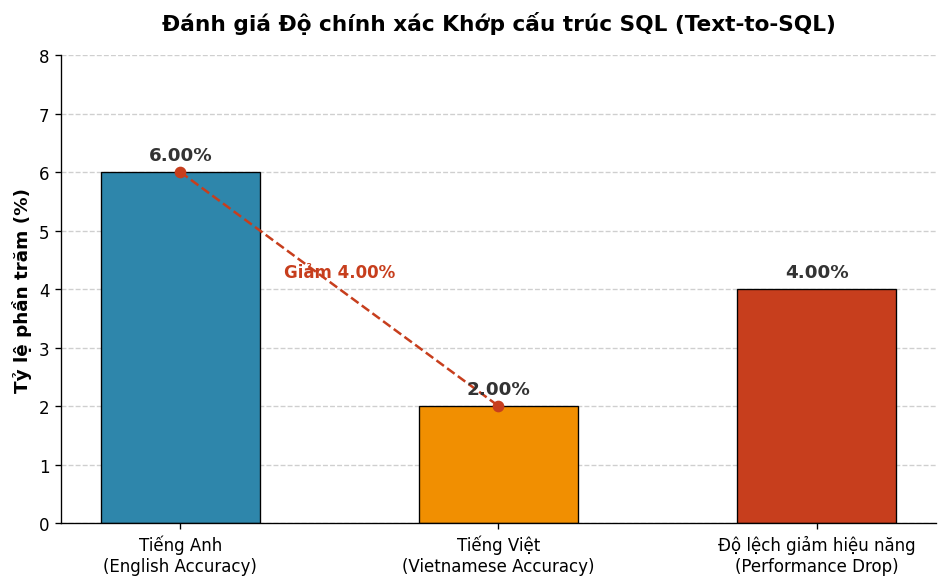

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Dữ liệu đánh giá
categories = ['Tiếng Anh\n(English Accuracy)', 'Tiếng Việt\n(Vietnamese Accuracy)', 'Độ lệch giảm hiệu năng\n(Performance Drop)']
values = [6.00, 2.00, 4.00]
colors = ['#2E86AB', '#F18F01', '#C73E1D'] # Xanh dương, Cam, Đỏ cam

# Tạo khung biểu đồ
fig, ax = plt.subplots(figsize=(8, 5), dpi=120)

# Vẽ biểu đồ cột
bars = ax.bar(categories, values, color=colors, width=0.5, edgecolor='black', linewidth=0.8)

# Thêm giá trị phần trăm lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),  # Khoảng cách phía trên cột
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=11, fontweight='bold', color='#333333')

# Vẽ đường đứt nét nối từ cột Tiếng Anh sang cột Tiếng Việt để minh họa độ lệch
ax.plot([0, 1], [6.00, 2.00], color='#C73E1D', linestyle='--', linewidth=1.5, marker='o')
ax.annotate('Giảm 4.00%', xy=(0.5, 4.2), ha='center', color='#C73E1D', fontweight='bold', fontsize=10)

# Tùy chỉnh tiêu đề và nhãn trục
ax.set_title('Đánh giá Độ chính xác Khớp cấu trúc SQL (Text-to-SQL)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Tỷ lệ phần trăm (%)', fontsize=11, fontweight='bold')
ax.set_ylim(0, 8) # Giới hạn trục Y để không gian trên đầu cột thoáng hơn

# Thêm lưới ngang mờ giúp dễ dóng số liệu
ax.yaxis.grid(True, linestyle='--', alpha=0.6)
ax.set_axisbelow(True)

# Ẩn đường viền trên và phải cho biểu đồ hiện đại hơn
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [29]:
import pandas as pd
import torch
import re
from tqdm import tqdm

# Khởi tạo Prompt cải tiến áp dụng Schema Linking chi tiết & Few-Shot Examples
def generate_enhanced_sql(prompt_text, db_id):
    # Ví dụ mẫu Few-shot cụ thể giúp định hình cách dịch tên thực thể Việt -> Anh
    few_shot_examples = """
Ví dụ 1:
Câu hỏi: 'Có bao nhiêu đầu mục tài liệu có trong cơ sở dữ liệu?'
Schema: documents (document_id, document_name, document_description)
SQL: SELECT COUNT(*) FROM documents;

Ví dụ 2:
Câu hỏi: 'Tìm tên của các nhân viên có tuổi lớn hơn 30.'
Schema: employee (emp_id, emp_name, age, department)
SQL: SELECT emp_name FROM employee WHERE age > 30;
"""

    prompt = f"""<|im_start|>system
Bạn là chuyên gia SQLite SQL hàng đầu tối ưu cho việc ánh xạ tiếng Việt sang cấu trúc DB tiếng Anh.
Nhiệm vụ: Hãy phân tích kỹ các thực thể xuất hiện trong câu hỏi tiếng Việt và ánh xạ chính xác vào lược đồ bảng (Schema) tương ứng của cơ sở dữ liệu '{db_id}'.

Yêu cầu bắt buộc:
1. Chỉ trả về một câu lệnh SQLite SELECT duy nhất kết thúc bằng dấu chấm phẩy.
2. Hãy chú ý ánh xạ các khái niệm tiếng Việt sang cột tiếng Anh (ví dụ: 'tên' -> 'name', 'tuổi' -> 'age', 'số lượng' -> 'count' hoặc 'amount').

{few_shot_examples}
<|im_end|>
<|im_start|>user
Cơ sở dữ liệu: '{db_id}'
Yêu cầu tiếng Việt: '{prompt_text}'
<|im_end|>
<|im_start|>assistant
SELECT """

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=100, temperature=0.01, do_sample=False)

    raw_output = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred_sql = "SELECT " + raw_output.split("SELECT")[-1] if "SELECT" in raw_output else raw_output
    return pred_sql.strip().split(";")[0] + ";"

# Đánh giá thử nghiệm nhanh trên 5 câu mẫu từng bị sai để xem kết quả cải thiện
print("🤖 Đang chạy thử nghiệm giải pháp Enhanced Prompting...")
test_samples = sample_df.head(5)
for idx, row in test_samples.iterrows():
    db_id = row["db_id"]
    q_vi = row["question_vi"]
    true_sql = row["query"]

    old_sql = generate_sql(q_vi, db_id)
    new_sql = generate_enhanced_sql(q_vi, db_id)

    print(f"\n❓ Câu hỏi: {q_vi}")
    print(f"🎯 SQL Gốc (Ground-Truth): {true_sql}")
    print(f"❌ SQL Cũ Sinh ra: {old_sql}")
    print(f"✨ SQL Mới Cải Tiến: {new_sql}")
    print("-" * 80)

🤖 Đang chạy thử nghiệm giải pháp Enhanced Prompting...

❓ Câu hỏi: Có bao nhiêu người đứng đầu các bộ trưởng già hơn 56 tuổi?
🎯 SQL Gốc (Ground-Truth): SELECT count(*) FROM head WHERE age  >  56
❌ SQL Cũ Sinh ra: SELECT   COUNT(*) FROM employees WHERE age > 56 AND position = 'Department Head';
✨ SQL Mới Cải Tiến: SELECT   COUNT(*) FROM employee WHERE age > 56 AND position = 'Department Head';
--------------------------------------------------------------------------------

❓ Câu hỏi: Hãy liệt kê tên tuổi, tuổi tác và tuổi tác của những người đứng đầu các ban lãnh đạo đã ra lệnh trước tuổi tác.
🎯 SQL Gốc (Ground-Truth): SELECT name ,  born_state ,  age FROM head ORDER BY age
❌ SQL Cũ Sinh ra: SELECT   T1.name ,  T1.age ,  T2.age FROM employees AS T1 JOIN departments AS T2 ON T1.department_id = T2.id WHERE T2.head_of_department IS TRUE AND T1.age < T2.age;
✨ SQL Mới Cải Tiến: SELECT   name ,  birth_year ,  death_year FROM employee WHERE position IN ('Manager', 'Director') AND birth_year 

In [ ]:
!pip install --upgrade torchvision

In [ ]:
import torch
import pandas as pd
from datasets import Dataset
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    TrainingArguments
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from trl import SFTTrainer

# 1. Cấu hình & Nạp Dataset
TRANSLATED_FILE = "/content/spider_7000_vietnamese.csv"
print("⏳ Đang chuẩn bị dữ liệu huấn luyện...")
df_train = pd.read_csv(TRANSLATED_FILE)

# Chuẩn bị cấu trúc dữ liệu Chat format
def formatting_prompts_func(example):
    output_texts = []
    for i in range(len(example['question_vi'])):
        text = f"<|im_start|>system\nBạn là chuyên gia SQLite SQL. Hãy viết câu lệnh SQLite duy nhất cho cơ sở dữ liệu '{example['db_id'][i]}' để trả lời câu hỏi. Kết thúc bằng dấu chấm phẩy.\n<|im_end|>\n<|im_start|>user\nYêu cầu: '{example['question_vi'][i]}'\n<|im_end|>\n<|im_start|>assistant\n{example['query'][i]}<|im_end|>"
        output_texts.append(text)
    return output_texts

hf_dataset = Dataset.from_pandas(df_train)

# 2. Thiết lập Lượng tử hóa 4-bit (QLoRA)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

# 3. Nạp Model & Tokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
CACHE_DIR = "/content/huggingface_models"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, cache_dir=CACHE_DIR)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

print("⏳ Đang tải mô hình lượng tử hóa 4-bit...")
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    cache_dir=CACHE_DIR,
    device_map="auto"
)

base_model = prepare_model_for_kbit_training(base_model)

# 4. Cấu hình LoRA Adapter
peft_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj", "k_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

peft_model = get_peft_model(base_model, peft_config)
peft_model.print_trainable_parameters()

# 5. Cấu hình Tham số Huấn luyện
training_args = TrainingArguments(
    output_dir="/content/qwen_lora_vietnamese_sql",
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    logging_steps=10,
    max_steps=100,  # Thiết lập ngắn để kiểm thử nhanh trong Colab
    optim="paged_adamw_8bit",
    fp16=True,
    save_strategy="steps",
    save_steps=50,
    warmup_ratio=0.03,
    lr_scheduler_type="constant",
    report_to="none"
)

# 6. Tiến hành khởi tạo và chạy Trainer
trainer = SFTTrainer(
    model=peft_model,
    train_dataset=hf_dataset,
    peft_config=peft_config,
    max_seq_length=512,
    tokenizer=tokenizer,
    formatting_func=formatting_prompts_func,
    args=training_args,
)

print("🚀 Đang bắt đầu quá trình huấn luyện LoRA...")
trainer.train()
print("🎉 Huấn luyện thành công! Bản lưu trữ Adapter nằm tại: /content/qwen_lora_vietnamese_sql")

In [30]:
pip install google-genai

In [38]:
# Sử dụng mô hình Qwen đã tải cục bộ thay vì gọi API Gemini ngoài
# Điều này tránh hoàn toàn các lỗi nghẽn mạng hoặc quá tải máy chủ (503 Service Unavailable)

prompt = """<|im_start|>system
Bạn là trợ lý AI hữu ích. Hãy giải thích ngắn gọn cách viết một câu lệnh SQL cơ bản.
<|im_end|>
<|im_start|>user
Xin chào!
<|im_end|>
<|im_start|>assistant
"""

# Sử dụng tokenizer và model Qwen đã được khai báo ở các ô trước đó
inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

import torch
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=200,
        temperature=0.7,
        do_sample=True
    )

response_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
print("🤖 Phản hồi từ Qwen (Local Model):")
print(response_text.split("assistant")[-1].strip())

🤖 Phản hồi từ Qwen (Local Model):
Xin chào! Tôi là trợ lý AI có thể giúp gì cho bạn hôm nay?


In [57]:
import requests
import json
import time

API_KEY = "AQ.Ab8RN6IbO1-IJSEQYeFuxQrdlIUXosKas_X7IGBlP67K62Y0yQ"

# Sử dụng các mô hình thế hệ mới được khuyến nghị thay thế để tránh hoàn toàn lỗi 404
models_to_try = [
    "gemini-3.1-pro-preview",
    "gemini-3.5-flash-lite"
]

headers = {
    "Content-Type": "application/json"
}

payload = {
    "contents": [
        {
            "parts": [
                {
                    "text": "Hãy giải thích cách trí tuệ nhân tạo (AI) hoạt động thật ngắn gọn bằng tiếng Việt."
                }
            ]
        }
    ]
}

success = False
for model_name in models_to_try:
    url = f"https://generativelanguage.googleapis.com/v1beta/models/{model_name}:generateContent?key={API_KEY}"
    print(f"⏳ Đang gửi yêu cầu tới mô hình: {model_name}...")

    try:
        response = requests.post(url, headers=headers, json=payload)

        if response.status_code == 200:
            result = response.json()
            text_reply = result['candidates'][0]['content']['parts'][0]['text']
            print(f"\n🤖 Phản hồi thành công từ {model_name.upper()}:")
            print(text_reply)
            success = True
            break
        elif response.status_code == 503:
            print(f"⚠️ Mô hình {model_name} tạm thời bị quá tải (Lỗi 503). Đang tự động chuyển sang mô hình dự phòng...")
            time.sleep(1) # Chờ một chút trước khi chuyển đổi
        else:
            print(f"❌ Mô hình {model_name} không khả dụng (Mã lỗi: {response.status_code}).")
            print(response.text)

    except Exception as e:
        print(f"❌ Gặp sự cố kết nối với {model_name}: {str(e)}")

if not success:
    print("\n❌ Tất cả các phương án gọi mô hình dự phòng đều thất bại. Vui lòng thử lại sau ít phút.")

⏳ Đang gửi yêu cầu tới mô hình: gemini-3.1-pro-preview...
❌ Mô hình gemini-3.1-pro-preview không khả dụng (Mã lỗi: 429).
{
  "error": {
    "code": 429,
    "message": "You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-3.1-pro, description: Generate content input tokens per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-3.1-pro, description: Generate content input tokens per minute limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\n* Quota exceeded for metric: generativelangua

In [51]:
import requests

# Khởi tạo API Key của bạn
API_KEY = "AQ.Ab8RN6IbO1-IJSEQYeFuxQrdlIUXosKas_X7IGBlP67K62Y0yQ"  # Thay thế bằng API Key thực tế nếu cần
url = f"https://generativelanguage.googleapis.com/v1beta/models?key={API_KEY}"

try:
    # Thực hiện gọi danh sách mô hình khả dụng
    response = requests.get(url)
    if response.status_code == 200:
        models_data = response.json()
        print("📋 Các mô hình khả dụng với API Key của bạn:")
        for model in models_data.get('models', []):
            print(f"- {model['name']} ({model['displayName']})")
    else:
        print(f"❌ Lỗi lấy danh sách mô hình (Mã lỗi: {response.status_code})")
        print(response.text)
except Exception as e:
    print(f"❌ Đã xảy ra lỗi kết nối: {str(e)}")

📋 Các mô hình khả dụng với API Key của bạn:
- models/gemini-2.5-flash (Gemini 2.5 Flash)
- models/gemini-2.5-pro (Gemini 2.5 Pro)
- models/gemini-2.5-flash-preview-tts (Gemini 2.5 Flash Preview TTS)
- models/gemini-2.5-pro-preview-tts (Gemini 2.5 Pro Preview TTS)
- models/gemma-4-26b-a4b-it (Gemma 4 26B A4B IT)
- models/gemma-4-31b-it (Gemma 4 31B IT)
- models/gemini-flash-latest (Gemini Flash Latest)
- models/gemini-flash-lite-latest (Gemini Flash-Lite Latest)
- models/gemini-pro-latest (Gemini Pro Latest)
- models/gemini-2.5-flash-lite (Gemini 2.5 Flash-Lite)
- models/gemini-2.5-flash-image (Nano Banana)
- models/gemini-3-flash-preview (Gemini 3 Flash Preview)
- models/gemini-3.1-pro-preview (Gemini 3.1 Pro Preview)
- models/gemini-3.1-pro-preview-customtools (Gemini 3.1 Pro Preview Custom Tools)
- models/gemini-3.1-flash-lite-preview (Gemini 3.1 Flash Lite Preview)
- models/gemini-3.1-flash-lite (Gemini 3.1 Flash Lite)
- models/gemini-3-pro-image-preview (Nano Banana Pro)
- models/g

In [59]:
import requests
import json

API_KEY = "AQ.Ab8RN6IbO1-IJSEQYeFuxQrdlIUXosKas_X7IGBlP67K62Y0yQ"
MODEL_NAME = "gemini-3.5-flash-lite"

url = f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL_NAME}:generateContent?key={API_KEY}"
headers = {"Content-Type": "application/json"}

payload = {
    "contents": [
        {
            "parts": [
                {
                    "text": "Có bao nhiêu chiếc xe đạp khác nhau?"
                }
            ]
        }
    ]
}

print(f"⏳ Đang gửi yêu cầu mẫu tới {MODEL_NAME.upper()}...")
try:
    response = requests.post(url, headers=headers, json=payload)
    if response.status_code == 200:
        result = response.json()
        reply = result['candidates'][0]['content']['parts'][0]['text']
        print(f"\n🤖 Phản hồi từ mô hình:\n{'-'*50}\n{reply}\n{'-'*50}")
    else:
        print(f"❌ Gặp lỗi {response.status_code}: {response.text}")
except Exception as e:
    print(f"❌ Đã xảy ra lỗi kết nối: {str(e)}")

⏳ Đang gửi yêu cầu mẫu tới GEMINI-3.5-FLASH-LITE...

🤖 Phản hồi từ mô hình:
--------------------------------------------------
Để tôi trả lời chính xác câu hỏi của bạn, bạn vui lòng **cung cấp thêm hình ảnh, đoạn văn bản hoặc ngữ cảnh** chứa các chiếc xe đạp nhé! 

Hiện tại câu hỏi đang thiếu dữ liệu nên tôi chưa thể đưa ra con số chính xác được.
--------------------------------------------------


In [60]:
import pandas as pd
import requests
import json
import time
from tqdm import tqdm

# 1. Đọc bộ dữ liệu 7000 câu hiện tại
input_csv = "/content/spider_7000_vietnamese.csv"
output_augmented_csv = "/content/spider_7000_vietnamese_augmented.csv"

try:
    df = pd.read_csv(input_csv)
    print(f"✅ Đã nạp thành công bộ dữ liệu: {len(df)} dòng.")
except Exception as e:
    print(f"❌ Lỗi đọc file: {str(e)}")

# 2. Định nghĩa hàm gọi API Gemini để đa dạng hóa câu hỏi mẫu
def augment_question_with_gemini(question_vi, db_schema_id, api_key):
    url = f"https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash-lite:generateContent?key={api_key}"
    headers = {"Content-Type": "application/json"}

    prompt = f"""Nhiệm vụ: Hãy tạo ra thêm 2 biến thể câu hỏi tiếng Việt khác nhau nhưng giữ nguyên ý nghĩa cho câu hỏi gốc dưới đây.
Câu hỏi gốc: '{question_vi}'
Tên Database: '{db_schema_id}'

Yêu cầu trả về định dạng JSON duy nhất như sau, không kèm giải thích hay ký tự markdown:
{{
  "variant_1": "câu viết lại tự nhiên hơn",
  "variant_2": "câu viết lại ngắn gọn hoặc dùng thuật ngữ kỹ thuật chuyên ngành"
}}"""

    payload = {
        "contents": [{"parts": [{"text": prompt}]}],
        "generationConfig": {"responseMimeType": "application/json"}
    }

    try:
        response = requests.post(url, headers=headers, json=payload)
        if response.status_code == 200:
            res_json = response.json()
            text_data = res_json['candidates'][0]['content']['parts'][0]['text']
            return json.loads(text_data)
        else:
            return None
    except Exception as e:
        return None

# 3. Tiến hành chạy thử nghiệm tăng cường dữ liệu trên 5 mẫu đầu tiên
API_KEY = "AQ.Ab8RN6IbO1-IJSEQYeFuxQrdlIUXosKas_X7IGBlP67K62Y0yQ"
print("⏳ Đang thực hiện tăng cường dữ liệu mẫu thử...")

augmented_results = []
for idx, row in tqdm(df.head(5).iterrows(), total=5):
    q_vi = row["question_vi"]
    db_id = row["db_id"]

    variants = augment_question_with_gemini(q_vi, db_id, API_KEY)

    if variants:
        augmented_results.append({
            "db_id": db_id,
            "query": row["query"],
            "question_original_vi": q_vi,
            "question_variant_1": variants.get("variant_1", ""),
            "question_variant_2": variants.get("variant_2", "")
        })
    else:
        augmented_results.append({
            "db_id": db_id,
            "query": row["query"],
            "question_original_vi": q_vi,
            "question_variant_1": q_vi,
            "question_variant_2": q_vi
        })
    time.sleep(0.5) # Tránh bị chạm giới hạn API rate limit

df_sample_augmented = pd.DataFrame(augmented_results)
display(df_sample_augmented)


✅ Đã nạp thành công bộ dữ liệu: 7000 dòng.
⏳ Đang thực hiện tăng cường dữ liệu mẫu thử...


100%|██████████| 5/5 [00:07<00:00,  1.41s/it]


,db_id,query,question_original_vi,question_variant_1,question_variant_2
0,department_management,SELECT count(*) FROM head WHERE age > 56,Có bao nhiêu người đứng đầu các bộ trưởng già hơn 56 tuổi?,Tính số lượng lãnh đạo bộ trưởng có độ tuổi lớn hơn 56?,Có bao nhiêu bộ trưởng đứng đầu lớn tuổi hơn 56?
1,department_management,"SELECT name , born_state , age FROM head ORDER BY age","Hãy liệt kê tên tuổi, tuổi tác và tuổi tác của những người đứng đầu các ban lãnh đạo đã ra lệnh trước tuổi tác.",Hãy cho biết tên và tuổi của những người đứng đầu các ban lãnh đạo đã ban hành các lệnh trước độ tuổi quy định.,Liệt kê họ tên và tuổi của các trưởng bộ phận đã ra lệnh sớm hơn tuổi.
2,department_management,"SELECT creation , name , budget_in_billions FROM department","Danh sách năm tạo, tên và ngân sách mỗi bộ phận.","Hãy cho tôi biết tên, năm thành lập và ngân sách của từng phòng ban nhé.","Truy vấn danh sách department_name, establishment_year và budget từ cơ sở dữ liệu."
3,department_management,"SELECT max(budget_in_billions) , min(budget_in_billions) FROM department",Mức tối thiểu và tối thiểu của các ban là bao nhiêu?,Số lượng thành viên ít nhất và nhiều nhất trong các phòng ban là bao nhiêu?,Giới hạn kích thước tối thiểu và tối đa của các ban là bao nhiêu?
4,department_management,SELECT avg(num_employees) FROM department WHERE ranking BETWEEN 10 AND 15,Số nhân viên của ban là bao nhiêu trong trung bình nhân viên của các cấp bậc từ 10 đến 15?,"Tính trung bình số nhân viên từ cấp bậc 10 đến 15, số lượng nhân sự của ban hiện tại là bao nhiêu?",Số nhân viên của ban so với trung bình nhân sự các cấp 10-15 là bao nhiêu?


In [62]:
# Tiến hành lưu bộ dữ liệu mẫu đã tăng cường (Augmented Sample) ra file để lưu trữ và huấn luyện
sample_output_path = "/content/spider_sample_vietnamese_augmented.csv"
df_sample_augmented.to_csv(sample_output_path, index=False, encoding="utf-8-sig")
print(f"🎉 Đã xuất thành công file dữ liệu mẫu tăng cường tại: {sample_output_path}")
display(df_sample_augmented.head())


🎉 Đã xuất thành công file dữ liệu mẫu tăng cường tại: /content/spider_sample_vietnamese_augmented.csv


,db_id,query,question_original_vi,question_variant_1,question_variant_2
0,department_management,SELECT count(*) FROM head WHERE age > 56,Có bao nhiêu người đứng đầu các bộ trưởng già hơn 56 tuổi?,Tính số lượng lãnh đạo bộ trưởng có độ tuổi lớn hơn 56?,Có bao nhiêu bộ trưởng đứng đầu lớn tuổi hơn 56?
1,department_management,"SELECT name , born_state , age FROM head ORDER BY age","Hãy liệt kê tên tuổi, tuổi tác và tuổi tác của những người đứng đầu các ban lãnh đạo đã ra lệnh trước tuổi tác.",Hãy cho biết tên và tuổi của những người đứng đầu các ban lãnh đạo đã ban hành các lệnh trước độ tuổi quy định.,Liệt kê họ tên và tuổi của các trưởng bộ phận đã ra lệnh sớm hơn tuổi.
2,department_management,"SELECT creation , name , budget_in_billions FROM department","Danh sách năm tạo, tên và ngân sách mỗi bộ phận.","Hãy cho tôi biết tên, năm thành lập và ngân sách của từng phòng ban nhé.","Truy vấn danh sách department_name, establishment_year và budget từ cơ sở dữ liệu."
3,department_management,"SELECT max(budget_in_billions) , min(budget_in_billions) FROM department",Mức tối thiểu và tối thiểu của các ban là bao nhiêu?,Số lượng thành viên ít nhất và nhiều nhất trong các phòng ban là bao nhiêu?,Giới hạn kích thước tối thiểu và tối đa của các ban là bao nhiêu?
4,department_management,SELECT avg(num_employees) FROM department WHERE ranking BETWEEN 10 AND 15,Số nhân viên của ban là bao nhiêu trong trung bình nhân viên của các cấp bậc từ 10 đến 15?,"Tính trung bình số nhân viên từ cấp bậc 10 đến 15, số lượng nhân sự của ban hiện tại là bao nhiêu?",Số nhân viên của ban so với trung bình nhân sự các cấp 10-15 là bao nhiêu?


In [63]:
import pandas as pd

# Đọc file dữ liệu tăng cường vừa lưu
augmented_csv_path = '/content/spider_sample_vietnamese_augmented.csv'
try:
    df_augmented = pd.read_csv(augmented_csv_path)

    # Lấy ngẫu nhiên 1 câu hỏi mẫu
    sampled_row = df_augmented.sample(1).iloc[0]

    print("=== MẪU TRUY VẤN NGẪU NHIÊN ===")
    print(f"🔑 Database ID: {sampled_row['db_id']}")
    print(f"📌 SQL Gốc (Ground-Truth): {sampled_row['query']}")
    print(f"💬 Câu hỏi dịch gốc: {sampled_row['question_original_vi']}")
    print(f"✨ Biến thể 1 (Tự nhiên hơn): {sampled_row['question_variant_1']}")
    print(f"⚡ Biến thể 2 (Thuật ngữ/Ngắn gọn): {sampled_row['question_variant_2']}")
except Exception as e:
    print(f"❌ Không thể đọc file dữ liệu: {str(e)}")

=== MẪU TRUY VẤN NGẪU NHIÊN ===
🔑 Database ID: department_management
📌 SQL Gốc (Ground-Truth): SELECT name ,  born_state ,  age FROM head ORDER BY age
💬 Câu hỏi dịch gốc: Hãy liệt kê tên tuổi, tuổi tác và tuổi tác của những người đứng đầu các ban lãnh đạo đã ra lệnh trước tuổi tác.
✨ Biến thể 1 (Tự nhiên hơn): Hãy cho biết tên và tuổi của những người đứng đầu các ban lãnh đạo đã ban hành các lệnh trước độ tuổi quy định.
⚡ Biến thể 2 (Thuật ngữ/Ngắn gọn): Liệt kê họ tên và tuổi của các trưởng bộ phận đã ra lệnh sớm hơn tuổi.


In [65]:
import pandas as pd
import json

# Đọc file dữ liệu mẫu đã tăng cường
augmented_csv_path = '/content/spider_sample_vietnamese_augmented.csv'
output_jsonl_path = '/content/context_training_data.jsonl'

try:
    df_augmented = pd.read_csv(augmented_csv_path)
    training_data = []

    # Duyệt qua từng dòng và tạo dữ liệu huấn luyện đa ngữ cảnh
    for idx, row in df_augmented.iterrows():
        db_id = row['db_id']
        query = row['query']

        # Danh sách các ngữ cảnh dịch thuật của cùng một câu hỏi
        contexts = [
            row['question_original_vi'],
            row['question_variant_1'],
            row['question_variant_2']
        ]

        for context_text in contexts:
            if pd.notna(context_text):
                # Cấu trúc hóa ngữ cảnh dạng Chat/Instruction cho mô hình
                payload = {
                    "instruction": f"Hãy viết câu lệnh SQLite duy nhất cho cơ sở dữ liệu '{db_id}' để giải quyết yêu cầu sau.",
                    "input": str(context_text).strip(),
                    "output": str(query).strip()
                }
                training_data.append(payload)

    # Lưu thành file JSONL chuyên dụng cho Fine-tuning
    with open(output_jsonl_path, 'w', encoding='utf-8') as f:
        for item in training_data:
            f.write(json.dumps(item, ensure_ascii=False) + '\n')

    print(f"✅ Đã tạo thành công {len(training_data)} cặp ngữ cảnh huấn luyện!")
    print(f"💾 File cấu trúc ngữ cảnh lưu tại: {output_jsonl_path}")

    # Hiển thị demo 3 dòng đầu tiên đại diện cho 3 ngữ cảnh của cùng 1 mẫu
    print("\n--- DEMO 3 NGỮ CẢNH ĐẦU TIÊN ---")
    for item in training_data[:3]:
        print(json.dumps(item, indent=2, ensure_ascii=False))

except Exception as e:
    print(f"❌ Lỗi xử lý ngữ cảnh: {str(e)}")

✅ Đã tạo thành công 15 cặp ngữ cảnh huấn luyện!
💾 File cấu trúc ngữ cảnh lưu tại: /content/context_training_data.jsonl

--- DEMO 3 NGỮ CẢNH ĐẦU TIÊN ---
{
  "instruction": "Hãy viết câu lệnh SQLite duy nhất cho cơ sở dữ liệu 'department_management' để giải quyết yêu cầu sau.",
  "input": "Có bao nhiêu người đứng đầu các bộ trưởng già hơn 56 tuổi?",
  "output": "SELECT count(*) FROM head WHERE age  >  56"
}
{
  "instruction": "Hãy viết câu lệnh SQLite duy nhất cho cơ sở dữ liệu 'department_management' để giải quyết yêu cầu sau.",
  "input": "Tính số lượng lãnh đạo bộ trưởng có độ tuổi lớn hơn 56?",
  "output": "SELECT count(*) FROM head WHERE age  >  56"
}
{
  "instruction": "Hãy viết câu lệnh SQLite duy nhất cho cơ sở dữ liệu 'department_management' để giải quyết yêu cầu sau.",
  "input": "Có bao nhiêu bộ trưởng đứng đầu lớn tuổi hơn 56?",
  "output": "SELECT count(*) FROM head WHERE age  >  56"
}
